# EMA crossovers, honestly: a research walkthrough

The original notebook (`00_original_exploration.ipynb`) claimed that an **EMA50/200 crossover on NVDA
returned +505% vs +347% for buy-and-hold** over 2022-2024. This notebook takes that claim apart and
rebuilds it as a proper study, using only the `trendlab` package. Every number below comes from library code.
The notebook adds no backtest logic of its own.

| Step | Question |
|---|---|
| 1-2 | Can we reproduce the +505% exactly? |
| 3-4 | Which biases produced it, and how much does each one contribute? |
| 5 | What does the textbook 50/200 rule do on 30 years of SPY? |
| 6 | Is 50/200 a robust plateau or a lucky cell, once we account for searching? |
| 7 | Is the rule's edge over buy-and-hold statistically distinguishable from luck? |
| 8 | Does trend following work better as a diversified portfolio? |

The full specification is in `docs/METHODOLOGY.md`, and the long-form results are in `reports/report.html`.

## 1. Setup

All data is read from the committed parquet cache in `data/raw/` (Yahoo adjusted OHLCV and the FRED 3-month
T-bill rate). `TRENDLAB_OFFLINE=1` makes any cache miss an error, so the network is never touched.
`Context` is the experiments' shared plumbing: cached prices, the T-bill series and the research defaults
(**next-close fills, 5 bp per side, idle cash earns T-bills**).

In [1]:
import os
import tempfile
import time
import warnings
from pathlib import Path

os.environ.setdefault("TRENDLAB_OFFLINE", "1")  # read data/raw only, never download
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from trendlab import (
    BacktestConfig,
    BuyAndHold,
    CostModel,
    EMACrossover,
    TimeSeriesMomentum,
    run_backtest,
)
from trendlab import indicators, metrics, plotting, stats, validation
from trendlab.engine import evaluation_start
from trendlab.event_engine import legacy_notebook_backtest
from trendlab.experiments.common import ETF_COSTS, Context, costs_for
from trendlab.experiments.e03_parameter_robustness import FAST, SLOW
from trendlab.experiments.e08_multi_asset_portfolio import BLEND_W, VOL_WINDOW
from trendlab.portfolio import blend, portfolio_backtest, static_mix_backtest
from trendlab.universe import ASSETS, CORE

%matplotlib inline
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Experiments write figures/tables under ctx.out_dir; point it at a throwaway dir so reports/ is never touched.
ctx = Context(out_dir=Path(tempfile.mkdtemp(prefix="trendlab-nb-")))
rf = ctx.rf  # FRED DTB3, annualised yield
T0 = time.perf_counter()


def show(fig):
    # Render a trendlab Figure inline once, then close it.
    display(fig)
    plt.close(fig)


pct = "{:.1%}".format

snapshot = pd.DataFrame(
    {
        t: {
            "name": ASSETS[t]["name"],
            "class": ASSETS[t]["class"],
            "first": ctx.prices(t).index[0].date(),
            "last": ctx.prices(t).index[-1].date(),
            "bars": len(ctx.prices(t)),
        }
        for t in ["NVDA", *CORE]
    }
).T
print(f"Research end date: {ctx.end}; T-bill yield on that date: {rf.loc[:ctx.end].iloc[-1]:.2%}")
snapshot

Research end date: 2026-10-28; T-bill yield on that date: 4.21%


,name,class,first,last,bars
NVDA,NVIDIA,Single stock,1999-01-22,2026-10-28,6985
SPY,S&P 500,US equity,1993-01-29,2026-10-28,8495
QQQ,Nasdaq-100,US equity,1999-03-10,2026-10-28,6953
IWM,Russell 2000,US equity,2000-05-26,2026-10-28,6645
EFA,Developed ex-US,Intl equity,2001-08-27,2026-10-28,6330
EEM,Emerging markets,Intl equity,2003-04-14,2026-10-28,5924
IEF,7-10y Treasuries,Bonds,2002-07-30,2026-10-28,6102
TLT,20y+ Treasuries,Bonds,2002-07-30,2026-10-28,6102
GLD,Gold,Commodities,2004-11-18,2026-10-28,5520
DBC,Commodity basket,Commodities,2006-02-06,2026-10-28,5215


## 2. Reproduce the original claim

`event_engine.legacy_notebook_backtest` re-runs the original notebook line by line, with all of its biases:
EMAs seeded on the first close of a 3-year window, signals that fire only on the crossing day and fill at that
**same close**, whole shares, a $5 ticket per signal, and idle cash earning 0%. If we cannot reproduce +505%,
we cannot say anything useful about it.

In [2]:
WIN_START, WIN_END = "2022-01-01", "2025-01-01"
nvda = ctx.prices("NVDA")
window = nvda.loc[WIN_START:WIN_END]
legacy = legacy_notebook_backtest(window)

CLAIMED = {"EMA50/200 (notebook)": 5.051, "Buy & hold": 3.466}  # as printed in the original notebook
replica = pd.DataFrame(
    {
        "claimed total return": [pct(v) for v in CLAIMED.values()],
        "replicated total return": [pct(legacy["algo_total_return"]), pct(legacy["bnh_total_return"])],
        "final equity": [f"${legacy['algo_final']:,.0f}", f"${legacy['bnh_final']:,.0f}"],
        "max drawdown": [pct(legacy["algo_max_drawdown"]), pct(legacy["bnh_max_drawdown"])],
    },
    index=list(CLAIMED),
)
assert round(legacy["algo_total_return"], 3) == CLAIMED["EMA50/200 (notebook)"]
assert round(legacy["bnh_total_return"], 3) == CLAIMED["Buy & hold"]
display(replica)
print("Notebook fills (same-close, whole shares, $5 tickets):")
legacy["trades"].assign(date=lambda d: d["date"].dt.date).round(2)

,claimed total return,replicated total return,final equity,max drawdown
EMA50/200 (notebook),505.1%,505.1%,"$605,142",-27.0%
Buy & hold,346.6%,346.6%,"$446,554",-62.7%


Notebook fills (same-close, whole shares, $5 tickets):


,date,side,price,shares,fee,cash_after
0,2022-01-04,sell,29.17,0.0,5.0,99995.00
1,2023-02-08,buy,22.13,4518.0,5.0,2.12


The replica matches to 0.1%. Look at the fills: the notebook's first action is a **sell while flat** on the
second trading day of 2022, and its first buy comes in February 2023. The rule sat in cash through the entire
2022 crash. The next section shows that this outcome came from how the indicators were started, not from any
trend the rule detected.

## 3. The warm-up problem

An EMA is a recursion, `e_t = a·p_t + (1-a)·e_{t-1}` with `a = 2/(n+1)`, seeded with the first price. After `t`
bars the seed still carries weight `(1-a)^t`. For EMA200 that weight decays slowly, so for most of 2022 the
notebook's "EMA200" was largely the 3 January 2022 close. `indicators.ema_warmup` gives the number of bars
before the seed's weight falls below 1%.

EMA200 needs 461 bars (~1.8 trading years) before the seed weighs < 1%.


bars after seed,20,50,100,200,250,461
seed weight,81.9%,60.7%,36.8%,13.5%,8.2%,1.0%


Seeded vs warmed EMA200 on the first bar: +34.0%; max gap 34.0%; still > 5% apart on 219 of the first 252 bars.


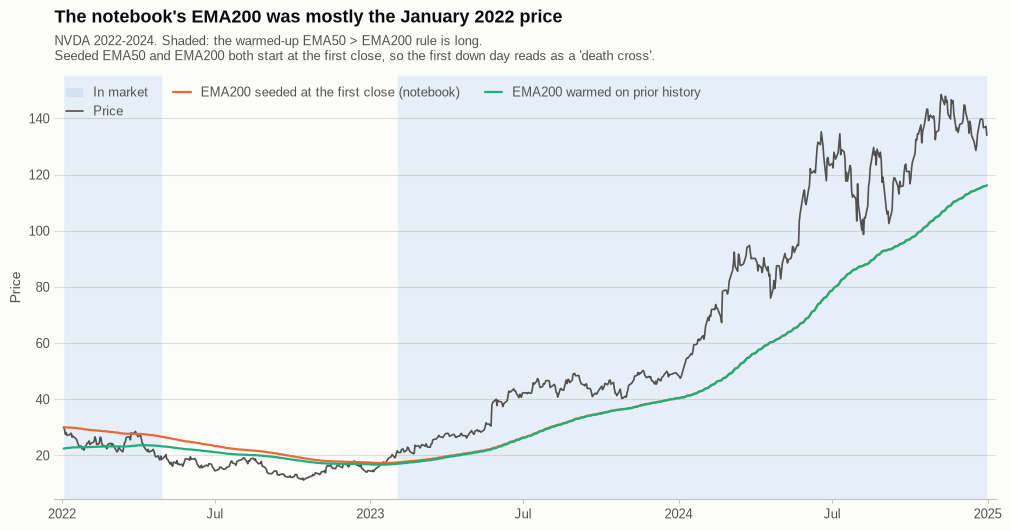

In [3]:
a200 = indicators.ema_alpha(200)
warm_bars = indicators.ema_warmup(200)
seed_weight = pd.Series({t: (1 - a200) ** t for t in [20, 50, 100, 200, 250, warm_bars]}, name="seed weight")
seed_weight.index.name = "bars after seed"
print(f"EMA200 needs {warm_bars} bars (~{warm_bars / 252:.1f} trading years) before the seed weighs < 1%.")
display(seed_weight.map(pct).to_frame().T)

seeded200 = indicators.ema(window["Close"], 200)              # what the notebook computed
warm200 = indicators.ema(nvda["Close"], 200).loc[window.index]  # warmed on all prior history
gap = (seeded200 / warm200 - 1).abs()
print(f"Seeded vs warmed EMA200 on the first bar: {seeded200.iloc[0] / warm200.iloc[0] - 1:+.1%}; "
      f"max gap {gap.max():.1%}; still > 5% apart on {int((gap.iloc[:252] > 0.05).sum())} of the first 252 bars.")

# The honest rule over the same window, frictionless same-close for now: warmed EMAs, long while EMA50 > EMA200.
warm_rule = run_backtest(
    nvda,
    EMACrossover(50, 200),
    BacktestConfig(execution="same_close", costs=CostModel.zero(), earn_cash_rate=False,
                   start=WIN_START, end=WIN_END),
)
show(plotting.price_with_signals(
    window, seeded200, warm200, warm_rule.exposure,
    log=False, markers=False,
    labels=("EMA200 seeded at the first close (notebook)", "EMA200 warmed on prior history"),
    title="The notebook's EMA200 was mostly the January 2022 price",
    subtitle="NVDA 2022-2024. Shaded: the warmed-up EMA50 > EMA200 rule is long.\n"
             "Seeded EMA50 and EMA200 both start at the first close, so the first down day reads as a 'death cross'.",
))

With warmed indicators, NVDA was already in an uptrend on 3 January 2022. An honest rule starts **invested**,
rides the first leg of the 2022 drawdown, and exits in late April. The notebook's +505% came from a
bear-market sidestep that happened only because both EMAs were seeded on 3 January 2022.

## 4. Fix execution and costs: the bias waterfall

We remove the biases one at a time, cumulatively, on the same NVDA window, using the vectorised engine
(`run_backtest` via `Context.pair`, which also runs buy-and-hold over the identical window):

1. warmed EMAs and the *state* rule (long while EMA50 > EMA200), still same-close, frictionless, 0% cash
2. fills at the **next** close: you cannot trade on the close you need in order to compute the signal
3. 5 bp per side (1 bp commission + 2 bp half-spread + 2 bp slippage)
4. idle cash earns the 3-month T-bill rate (this step helps the rule)

,total_return,max_drawdown,n_trades,B&H total_return
0. Original notebook,505.1%,-27.0%,1,346.6%
"1. Warm EMAs, state rule",281.2%,-41.4%,2,346.6%
2. + Next-close fills,313.1%,-38.9%,2,346.6%
3. + 5 bp/side costs,312.5%,-38.9%,2,346.3%
4. + T-bill cash,322.2%,-38.9%,2,346.3%


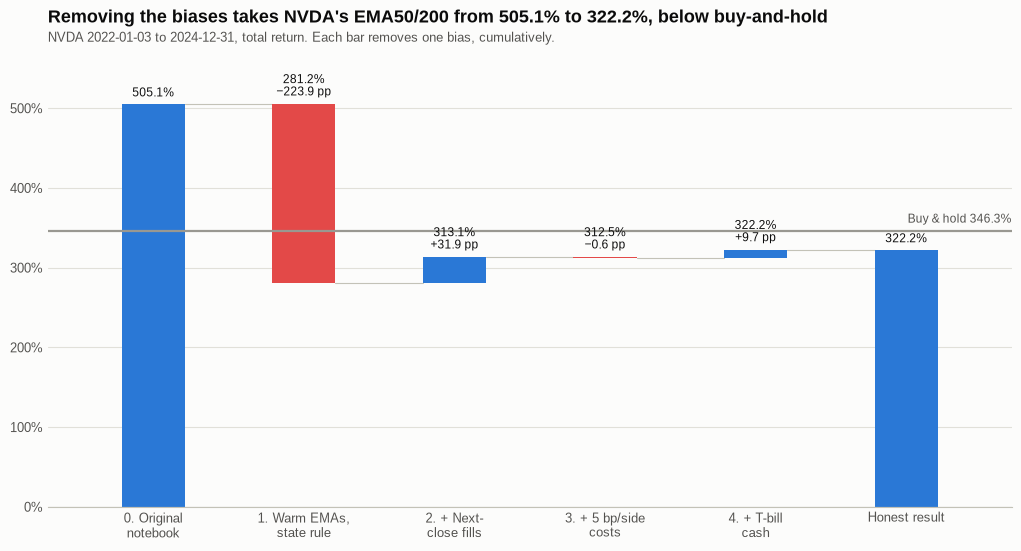

In [4]:
strat = EMACrossover(50, 200)
window_kw = {"start": WIN_START, "end": WIN_END}
STEPS = {
    "1. Warm EMAs, state rule": {"execution": "same_close", "costs": CostModel.zero(), "earn_cash_rate": False},
    "2. + Next-close fills": {"execution": "next_close", "costs": CostModel.zero(), "earn_cash_rate": False},
    "3. + 5 bp/side costs": {"execution": "next_close", "costs": costs_for("NVDA"), "earn_cash_rate": False},
    "4. + T-bill cash": {"execution": "next_close", "costs": costs_for("NVDA"), "earn_cash_rate": True},
}
results = {label: ctx.pair("NVDA", strat, **window_kw, **kw) for label, kw in STEPS.items()}

rows = {"0. Original notebook": {
    "total_return": legacy["algo_total_return"],
    "max_drawdown": legacy["algo_max_drawdown"],
    "n_trades": int((legacy["trades"]["side"] == "buy").sum()),
    "bnh_total_return": legacy["bnh_total_return"],
}}
for label, (res, bnh) in results.items():
    s = res.summary()
    rows[label] = {
        "total_return": s["total_return"], "max_drawdown": s["max_drawdown"],
        "n_trades": s["n_trades"], "bnh_total_return": bnh.summary()["total_return"],
    }
waterfall = metrics.format_table(rows).rename(columns={"bnh_total_return": "B&H total_return"})
waterfall["B&H total_return"] = [pct(r["bnh_total_return"]) for r in rows.values()]
display(waterfall)

honest, honest_bnh = results["4. + T-bill cash"]
show(plotting.bias_waterfall(
    [(label, r["total_return"]) for label, r in rows.items()],
    benchmark=honest_bnh.summary()["total_return"],
    title=f"Removing the biases takes NVDA's EMA50/200 from {pct(legacy['algo_total_return'])} "
          f"to {pct(rows['4. + T-bill cash']['total_return'])}, below buy-and-hold",
    subtitle="NVDA 2022-01-03 to 2024-12-31, total return. Each bar removes one bias, cumulatively.",
))

In [5]:
# Side check: how sensitive is the honest result to *when* the fill happens? (costs + T-bills on)
timing = {
    ex: ctx.backtest("NVDA", strat, execution=ex, **window_kw).summary()
    for ex in ("same_close", "next_open", "next_close")
}
display(metrics.format_table(timing, ["total_return", "cagr", "max_drawdown", "sharpe", "n_trades"]))
print("Honest rule vs buy-and-hold over the notebook window:")
metrics.format_table(
    {"EMA50/200 (honest)": honest.summary(honest_bnh), "Buy & hold": honest_bnh.summary()},
    ["total_return", "cagr", "vol", "sharpe", "max_drawdown", "exposure", "n_trades"],
)

,total_return,cagr,max_drawdown,sharpe,n_trades
same_close,289.6%,57.7%,-40.1%,1.13,2
next_open,300.6%,59.2%,-39.2%,1.15,2
next_close,322.2%,62.0%,-38.9%,1.19,2


Honest rule vs buy-and-hold over the notebook window:


,total_return,cagr,vol,sharpe,max_drawdown,exposure,n_trades
EMA50/200 (honest),322.2%,62.0%,45.6%,1.19,-38.9%,74.5%,2
Buy & hold,346.3%,65.1%,55.2%,1.10,-62.7%,99.9%,1


**Takeaway.** Almost the entire edge over buy-and-hold came from step 1: the notebook started 2022 in cash
by construction, because its seeded EMAs crossed on day two and its cross-only entry waits for a fresh golden
cross. The report's 2x2 table (`e01`) shows that either flaw alone is enough. Execution timing moves the result
by tens of points either way, which is noise when there are only two round trips. After the fixes, the
rule *trails* buy-and-hold on total return and roughly ties it on Sharpe, with a much smaller drawdown. NVDA
is also a hindsight-selected asset, so from here on we use broad, pre-specified markets.

## 5. SPY, full history: what the golden cross actually does

Same rule, research defaults, SPY from inception (1993) with the warm-up period excluded. Buy-and-hold uses the
identical window.

,start,end,cagr,vol,sharpe,sortino,max_drawdown,calmar,max_dd_bars,exposure,n_trades,hit_rate,beta,alpha,alpha_t
EMA50/200,1994-11-28,2026-10-28,10.3%,14.1%,0.59,0.81,-36.3%,0.28,804,80.7%,13,76.9%,0.56,2.8%,1.66
Buy & hold,1994-11-28,2026-10-28,11.2%,18.9%,0.53,0.74,-55.2%,0.20,1656,100.0%,1,100.0%,–,–,–


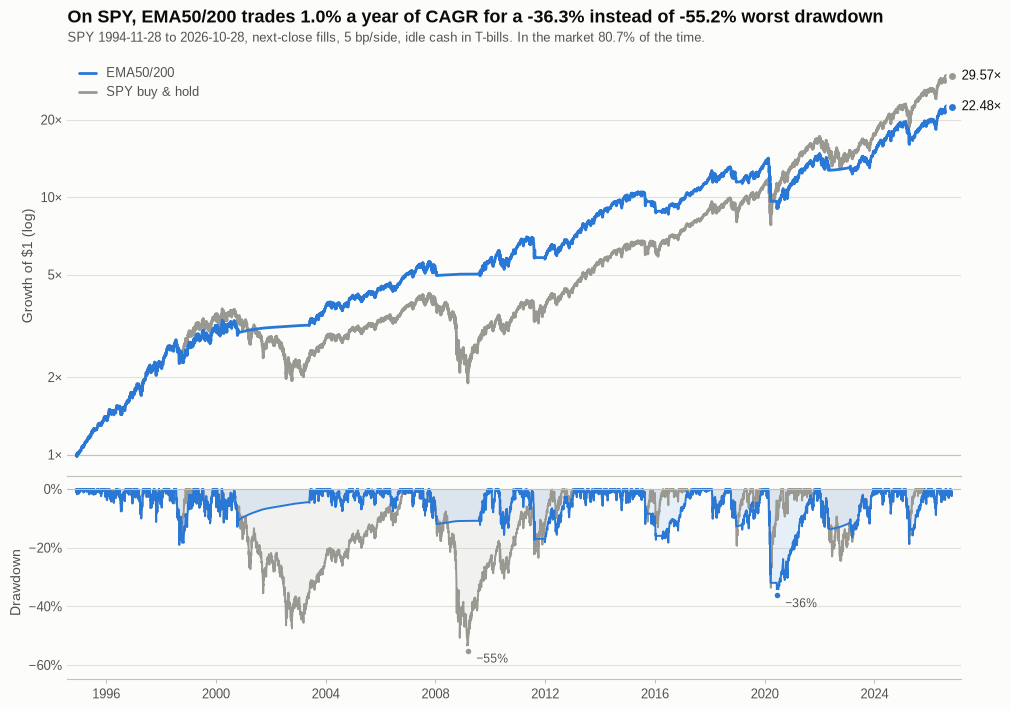

In [6]:
spy_res, spy_bnh = ctx.pair("SPY", EMACrossover(50, 200))
KEYS = ["start", "end", "cagr", "vol", "sharpe", "sortino", "max_drawdown", "calmar", "max_dd_bars",
        "exposure", "n_trades", "hit_rate", "beta", "alpha", "alpha_t"]
spy_s, bnh_s = spy_res.summary(spy_bnh), spy_bnh.summary()
display(metrics.format_table({"EMA50/200": spy_s, "Buy & hold": bnh_s}, KEYS))

show(plotting.equity_and_drawdown(
    {"EMA50/200": spy_res.equity, "SPY buy & hold": spy_bnh.equity},
    title=f"On SPY, EMA50/200 trades {pct(bnh_s['cagr'] - spy_s['cagr'])} a year of CAGR for a "
          f"{pct(spy_s['max_drawdown'])} instead of {pct(bnh_s['max_drawdown'])} worst drawdown",
    subtitle=f"SPY {spy_s['start']} to {spy_s['end']}, next-close fills, 5 bp/side, idle cash in T-bills. "
             f"In the market {pct(spy_s['exposure'])} of the time.",
))

This is the honest profile of a slow trend filter on equities. It gives up some CAGR and sidesteps a large
part of the slow 2000-02 and 2007-09 bear markets, because it sits in T-bills while the trend is down. Fast
V-shaped crashes such as COVID in 2020 are another matter: the rule exits late and re-enters late. Its Sharpe is
slightly higher than buy-and-hold's, and its regression alpha is positive, but the alpha t-statistic is below 2.
Section 7 tests whether the small Sharpe gap is real.

## 6. Is 50/200 special? Parameter grid and the deflated Sharpe ratio

We evaluate 62 (fast, slow) EMA pairs on SPY over one common window that starts once the slowest rule has
warmed up. The 50/200 rule is fixed **a priori**. If the rule captures something real, neighbouring cells
should look alike (a plateau rather than a spike). Choosing the best cell *after* looking is a multiple-testing
problem, so we judge it with the **deflated Sharpe ratio** (Bailey & López de Prado 2014), which raises the bar
to the Sharpe you would expect from the best of N noisy trials. The **probability of backtest overfitting**
(CSCV, Bailey et al. 2017) asks how often the in-sample winner falls below the median out of sample.

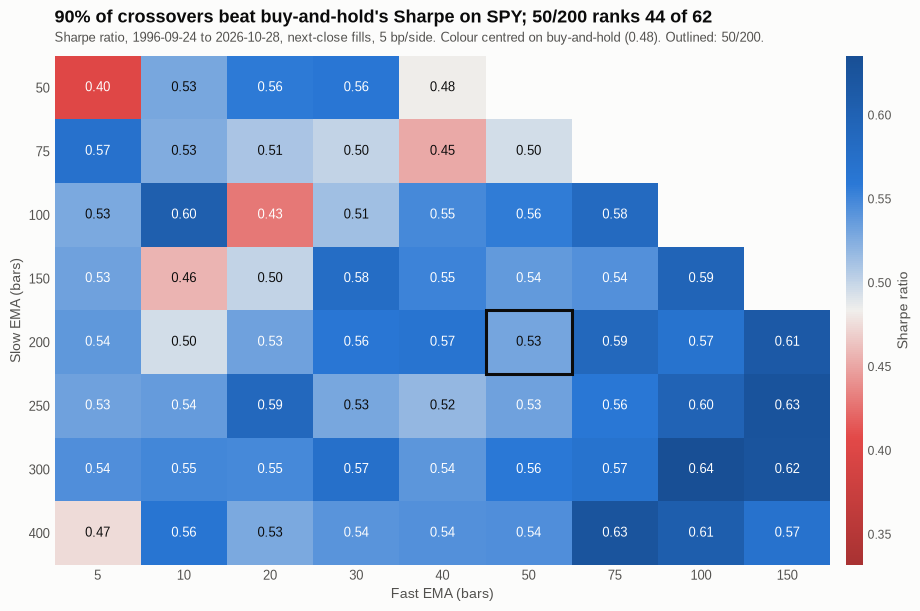

In [7]:
spy = ctx.prices("SPY")
grid = validation.parameter_grid(FAST, SLOW)
gm = validation.grid_metrics(spy, grid, ctx.config("SPY"), rf)
rets = validation.grid_returns(spy, grid, ctx.config("SPY"), rf)
grid_bnh = ctx.backtest("SPY", BuyAndHold(), start=rets.index[0])
rf_g = grid_bnh.rf.reindex(rets.index)
bnh_sharpe = metrics.sharpe(grid_bnh.returns, rf_g)

piv = validation.grid_pivot(gm, "sharpe")
tb = "EMA50/200"
rank = int((gm["sharpe"] > gm.at[tb, "sharpe"]).sum() + 1)
show(plotting.metric_heatmap(
    piv, fmt="{:.2f}", center=bnh_sharpe, mark=(50, 200),
    title=f"{(gm['sharpe'] > bnh_sharpe).mean():.0%} of crossovers beat buy-and-hold's Sharpe on SPY; "
          f"50/200 ranks {rank} of {len(gm)}",
    subtitle=f"Sharpe ratio, {rets.index[0].date()} to {rets.index[-1].date()}, next-close fills, 5 bp/side. "
             f"Colour centred on buy-and-hold ({bnh_sharpe:.2f}). Outlined: 50/200.",
    cbar_label="Sharpe ratio", xlabel="Fast EMA (bars)", ylabel="Slow EMA (bars)",
))

In [8]:
best = str(gm["sharpe"].idxmax())
# Absolute null: is the best cell's Sharpe (excess of T-bills) > 0 after accounting for 62 trials?
dsr_abs = stats.deflated_sharpe_ratio(rets[best], stats.trial_sharpes(rets, rf_g), rf=rf_g)
# Relative null: does the best cell beat *buy-and-hold* (returns in excess of B&H) after 62 trials?
active = rets.sub(grid_bnh.returns.reindex(rets.index), axis=0)
ts_act = stats.trial_sharpes(active)
best_act = str(ts_act.idxmax())
dsr_rel = stats.deflated_sharpe_ratio(active[best_act], ts_act)
pbo = stats.pbo_cscv(rets, n_blocks=16, rf=rf_g)

display(pd.DataFrame(
    {
        "best cell": [best, best_act],
        "observed annual Sharpe / IR": [dsr_abs["sr_annual"], dsr_rel["sr_annual"]],
        "hurdle SR0 (best of 62 by luck)": [dsr_abs["sr0_annual"], dsr_rel["sr0_annual"]],
        "deflated Sharpe ratio (prob.)": [dsr_abs["dsr"], dsr_rel["dsr"]],
    },
    index=["vs T-bills (is it profitable?)", "vs buy-and-hold (does timing add value?)"],
).round(3))
print(f"Cells with a higher Sharpe than B&H: {(gm['sharpe'] > bnh_sharpe).mean():.0%}; "
      f"cells with positive mean return in excess of B&H: {(ts_act > 0).mean():.0%}")
print(f"Probability of backtest overfitting (CSCV, {pbo['n_combinations']:,} splits): {pbo['pbo']:.0%}; "
      f"in-sample winner's Sharpe {np.mean(pbo['is_metric']) * np.sqrt(252):.2f} -> "
      f"out of sample {np.mean(pbo['oos_metric']) * np.sqrt(252):.2f}")

,best cell,observed annual Sharpe / IR,hurdle SR0 (best of 62 by luck),deflated Sharpe ratio (prob.)
vs T-bills (is it profitable?),EMA100/300,0.635,0.109,0.998
vs buy-and-hold (does timing add value?),EMA100/300,0.034,0.175,0.221


Cells with a higher Sharpe than B&H: 90%; cells with positive mean return in excess of B&H: 10%
Probability of backtest overfitting (CSCV, 12,870 splits): 76%; in-sample winner's Sharpe 0.70 -> out of sample 0.50


**Reading the results.** Against T-bills the best cell is clearly profitable, but that only says that being
long US equities paid off. The interesting null is *against buy-and-hold*. Most cells have a higher Sharpe than
B&H because they carry less volatility, yet very few earn more than B&H in absolute terms. Even the best of 62
timing variants fails to clear the deflated hurdle. A PBO well above 50% means that the in-sample winner usually
lands below the median out of sample. The grid is a broad plateau, so no window choice is magic, and 50/200 is
nothing special within it.

## 7. Significance: is the Sharpe gap vs buy-and-hold real?

We run two complementary tests on the full-history SPY result from Section 5:

* **Paired stationary bootstrap** (Politis & Romano 1994; mean block 20 days). Both return streams are
  resampled with the *same* indices, which preserves their correlation and volatility clustering. The output is
  a confidence interval and a one-sided p-value for `SR(rule) − SR(B&H)`.
* **Random-entry Monte Carlo.** We keep the rule's exact trades (count, holding periods, exposure) and shuffle
  *when* they happen. This tests whether the timing beats chance, given how much the rule is in the market.

,statistic,null / interval,p-value
"Sharpe(EMA50/200) − Sharpe(B&H), bootstrap",+0.062,"95% CI [-0.17, +0.31]",0.324
EMA50/200 Sharpe vs random placement of its 13 trades,0.588,random-timing mean 0.465,0.078


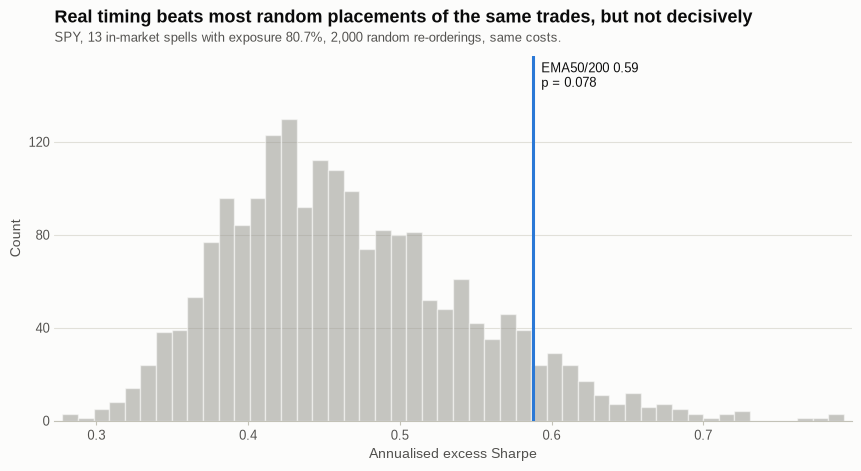

In [9]:
boot = stats.bootstrap_sharpe_difference(
    spy_res.returns, spy_bnh.returns, rf=spy_res.rf, n_boot=2000, mean_block=20, seed=0
)
rnd = stats.random_entry_test_result(spy_res, n_sims=2000, seed=0)

display(pd.DataFrame(
    {
        "statistic": [f"{boot['diff']:+.3f}", f"{rnd['actual_sharpe']:.3f}"],
        "null / interval": [f"95% CI [{boot['ci_low']:+.2f}, {boot['ci_high']:+.2f}]",
                            f"random-timing mean {rnd['null_mean']:.3f}"],
        "p-value": [f"{boot['p_value']:.3f}", f"{rnd['p_value']:.3f}"],
    },
    index=["Sharpe(EMA50/200) − Sharpe(B&H), bootstrap",
           f"EMA50/200 Sharpe vs random placement of its {rnd['n_segments']} trades"],
))
show(plotting.histogram_with_marker(
    rnd["null_sharpes"], rnd["actual_sharpe"], p_value=rnd["p_value"],
    title="Real timing beats most random placements of the same trades, but not decisively",
    subtitle=f"SPY, {rnd['n_segments']} in-market spells with exposure {pct(rnd['exposure_fraction'])}, "
             "2,000 random re-orderings, same costs.",
    xlabel="Annualised excess Sharpe", actual_label="EMA50/200",
))

The bootstrap confidence interval for the Sharpe gain comfortably straddles zero. Thirty years of SPY cannot
distinguish the golden cross from buy-and-hold on a risk-adjusted basis. The random-entry test is more
favourable: the rule's timing sits in the right tail of random timing, but it misses the 5% level. The
defensible claim is **"similar Sharpe, smaller drawdowns"**, not "beats the market". The report
(`e09_significance`) repeats both tests across all assets with Holm and Benjamini–Hochberg corrections.

## 8. Trend as a portfolio: ten markets vs 60/40

Practitioners trade trend as a *portfolio* of many weakly correlated bets (Moskowitz, Ooi & Pedersen 2012).
Below, each of the ten pre-specified CORE ETFs (equities, bonds, gold, commodities, REITs) gets an EMA50/200
sleeve, long or in T-bills, weighted by inverse 63-day volatility and rebalanced monthly. We compare it with a
monthly-rebalanced 60/40 SPY/IEF and with an 80/20 blend of the two.

,start,cagr,vol,sharpe,max_drawdown,calmar,correlation,beta
Trend EMA50/200 (10 ETFs),2004-05-28,6.0%,7.0%,0.60,-15.0%,0.40,0.61,0.41
60/40 benchmark,2004-05-28,8.2%,10.5%,0.62,-32.6%,0.25,1.00,1.00
80% 60/40 + 20% trend,2004-05-28,7.7%,9.3%,0.65,-26.3%,0.29,0.99,0.88


Calendar-year returns in the stress years:


,Trend EMA50/200 (10 ETFs),60/40 benchmark,80% 60/40 + 20% trend
Date,,,
2008,7.2%,-18.0%,-13.4%
2020,0.7%,16.0%,12.8%
2022,-3.9%,-16.7%,-14.1%


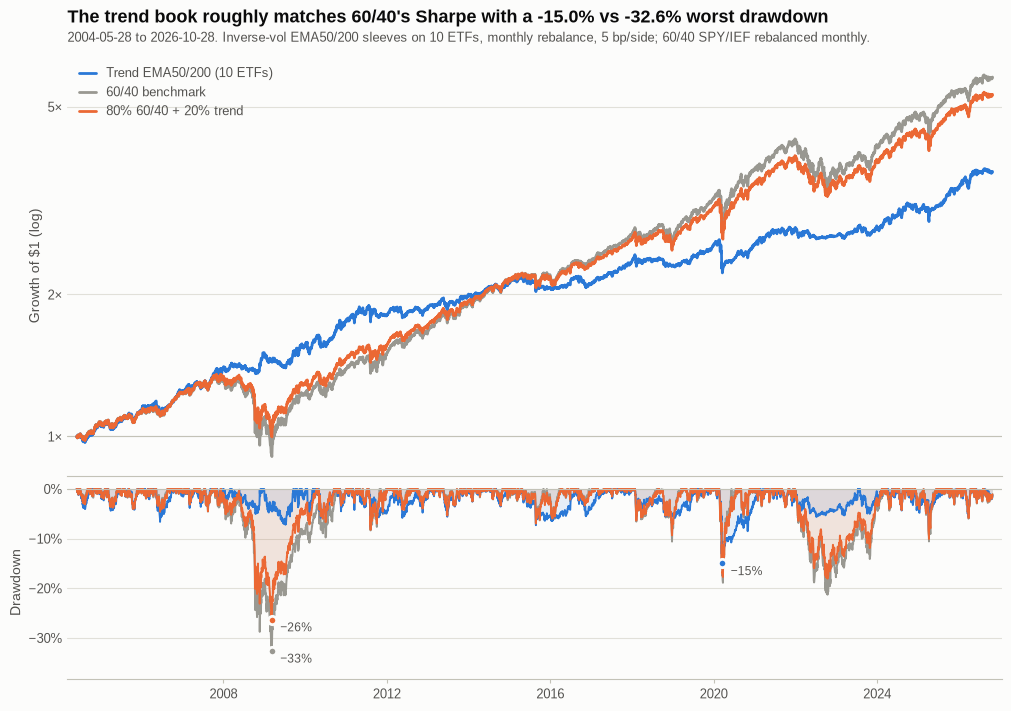

Notebook run time so far: 6 s


In [10]:
prices = {t: ctx.prices(t) for t in CORE}
ema = EMACrossover(50, 200)
start = max(evaluation_start(prices[t], [ema, TimeSeriesMomentum(252)]) for t in ("SPY", "IEF"))
common = {"costs": {t: costs_for(t) for t in CORE}, "rf_yield": rf, "start": start, "end": ctx.end,
          "calendar": "SPY"}

trend = portfolio_backtest(prices, ema, weighting="inverse_vol", vol_window=VOL_WINDOW, rebalance="ME",
                           name="Trend EMA50/200 (10 ETFs)", **common)
sixty = static_mix_backtest(prices, {"SPY": 0.6, "IEF": 0.4}, name="60/40 benchmark", **common)
mix = blend(sixty.returns, trend.returns, BLEND_W, "ME", cost_bps=ETF_COSTS.bps)
mix = mix.rename(f"{BLEND_W:.0%} 60/40 + {1 - BLEND_W:.0%} trend")

streams = {trend.name: trend.returns, sixty.name: sixty.returns, mix.name: mix}
rows = {k: metrics.summary(r, rf=sixty.rf, benchmark=sixty.returns) for k, r in streams.items()}
display(metrics.format_table(rows, ["start", "cagr", "vol", "sharpe", "max_drawdown", "calmar",
                                    "correlation", "beta"]))

yearly = pd.DataFrame({k: (1 + r).resample("YE").prod() - 1 for k, r in streams.items()})
yearly.index = yearly.index.year
print("Calendar-year returns in the stress years:")
display(yearly.loc[[2008, 2020, 2022]].map(pct))

show(plotting.equity_and_drawdown(
    streams,
    title=f"The trend book roughly matches 60/40's Sharpe with a "
          f"{pct(rows[trend.name]['max_drawdown'])} vs {pct(rows[sixty.name]['max_drawdown'])} worst drawdown",
    subtitle=f"{start.date()} to {ctx.end}. Inverse-vol EMA50/200 sleeves on 10 ETFs, monthly rebalance, "
             "5 bp/side; 60/40 SPY/IEF rebalanced monthly.",
))
print(f"Notebook run time so far: {time.perf_counter() - T0:.0f} s")

Diversifying across asset classes is what makes trend following work. The ten-market book has low volatility,
a much shallower drawdown than 60/40, and it held up in 2008 and 2022, the two years when the 60/40 investor
needed help (in 2022, stocks and bonds fell together). The cost is visible in 2020, when it missed the V-shaped
rebound. It does not beat 60/40 on Sharpe. In the report, an always-long inverse-vol book of the same ETFs has
a similar Sharpe, so much of the benefit comes from diversification and the bond tilt rather than from the
signal. As a 20% overlay it modestly improves both the Sharpe and the drawdown of 60/40.

## 9. Conclusions

1. **The +505% was an artefact.** It reproduces exactly, but it came from EMAs seeded on the first day of the
   window, which kept the rule in cash through the 2022 crash. With warmed indicators, realistic fills and costs, the rule *trails* NVDA buy-and-hold over the
   same window.
2. **On SPY the golden cross is a risk filter, not an alpha source.** Its Sharpe is similar to buy-and-hold's,
   its drawdowns are much smaller, and it gives up some CAGR. Neither the bootstrap nor the deflated Sharpe
   ratio can separate its risk-adjusted edge from zero.
3. **Parameters don't matter much, and searching for them doesn't help.** The grid is a plateau, the best cell
   fails the deflated hurdle against buy-and-hold, and PBO is high.
4. **Trend earns its keep as a diversified portfolio.** It delivers low volatility, shallow drawdowns and
   crisis convexity, which makes it a complement to 60/40 rather than a replacement.

**Where to go next**

* `reports/report.html` contains all ten experiments, including cross-asset results, walk-forward
  out-of-sample tests, crises and VIX regimes, alternative signals, vol targeting and cost sensitivity.
  Regenerate it with `trendlab run`.
* `docs/METHODOLOGY.md` gives exact definitions of execution, accounting, metrics and the statistical tests.
* `src/trendlab/` contains the engine (`engine.py`, cross-checked bar by bar against `event_engine.py`),
  `stats.py` (PSR, DSR, PBO, bootstrap, random-entry) and `portfolio.py`.

In [11]:
print(f"Total run time: {time.perf_counter() - T0:.0f} s")

Total run time: 6 s
